# Importing Libraries

In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

# Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Prophet
from prophet import Prophet

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings('ignore')

# Load dataset

In [ ]:
# Load dataset
health_df = pd.read_csv('health_indicators.csv')

print(health_df.shape)
health_df.head()

(5275, 48)


,country_code,country_name,region,income_level,year,population,population_growth,urban_pct,life_expectancy,life_expectancy_male,...,stunting_pct,wasting_pct,overweight_children_pct,undernourishment_pct,fertility_rate,adolescent_fertility,prenatal_care_pct,gdp_per_capita,gdp_per_capita_ppp,poverty_rate
0,ABW,Aruba,Latin America & Caribbean,High income,2000,90588.0,1.030817,65.354550,72.939,70.149,...,NaN,NaN,NaN,NaN,1.845,43.729,NaN,20681.023027,30245.706974,NaN
1,ABW,Aruba,Latin America & Caribbean,High income,2001,91439.0,0.935033,65.335114,73.044,70.251,...,NaN,NaN,NaN,NaN,1.813,40.463,NaN,20740.132583,31920.239073,NaN
2,ABW,Aruba,Latin America & Caribbean,High income,2002,92074.0,0.692052,65.282069,73.135,70.364,...,NaN,NaN,NaN,NaN,1.800,38.185,NaN,21307.248251,31888.508737,NaN
3,ABW,Aruba,Latin America & Caribbean,High income,2003,93128.0,1.138229,65.198292,73.236,70.488,...,NaN,NaN,NaN,NaN,1.808,37.807,NaN,21949.485996,32507.084315,NaN
4,ABW,Aruba,Latin America & Caribbean,High income,2004,95138.0,2.135358,65.088653,73.223,70.487,...,NaN,NaN,NaN,NaN,1.819,38.761,NaN,23700.631990,35059.273098,NaN


# Extract Kenya Data

In [ ]:
kenya_df = health_df.loc[
    health_df['country_name'].eq('Kenya'),
    [
        'year',
        'life_expectancy',
        'maternal_mortality',
        'under5_mortality',
        'health_expenditure_pct_gdp',
        'gdp_per_capita',
        'physicians_per_1000',
        'hospital_beds_per_1000',
        'nurses_per_1000',
        'population',
    ]
].copy()

kenya_df.head()


,year,life_expectancy,maternal_mortality,under5_mortality,health_expenditure_pct_gdp,gdp_per_capita,physicians_per_1000,hospital_beds_per_1000,nurses_per_1000,population
2400,2000,56.084,206.0,95.2,3.624514,414.626365,NaN,NaN,NaN,30642890.0
2401,2001,56.501,188.0,90.5,3.740023,410.700452,NaN,NaN,NaN,31619170.0
2402,2002,56.759,182.0,85.6,3.821595,402.936386,0.138,NaN,NaN,32629808.0
2403,2003,57.369,177.0,80.8,4.033657,442.898457,NaN,NaN,NaN,33652223.0
2404,2004,57.947,177.0,76.1,4.211595,463.662781,NaN,1.4,0.465,34713455.0


# Exploratory Data Analysis

In [ ]:
kenya_df.head()

kenya_df.info()

kenya_df.describe()

kenya_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 2400 to 2424
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   year                        25 non-null     int64  
 1   life_expectancy             25 non-null     float64
 2   maternal_mortality          24 non-null     float64
 3   under5_mortality            25 non-null     float64
 4   health_expenditure_pct_gdp  24 non-null     float64
 5   gdp_per_capita              25 non-null     float64
 6   physicians_per_1000         13 non-null     float64
 7   hospital_beds_per_1000      3 non-null      float64
 8   nurses_per_1000             16 non-null     float64
 9   population                  25 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 2.1 KB


year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
nurses_per_1000                9
population                     0
dtype: int64

MISSING VALUES

In [ ]:
missing_values = kenya_df.isnull().sum()
print(missing_values)

year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
nurses_per_1000                9
population                     0
dtype: int64


In [ ]:
# Handle missing values for numeric columns by converting them to numeric types and imputing with median values
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns
kenya_df[numeric_cols] = kenya_df[numeric_cols].apply(pd.to_numeric, errors='coerce')

In [ ]:
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns

imputer = SimpleImputer(strategy='median')

nonempty_numeric_cols = kenya_df[numeric_cols].columns[
    kenya_df[numeric_cols].notna().any()
]

kenya_df[nonempty_numeric_cols] = imputer.fit_transform(
    kenya_df[nonempty_numeric_cols]
)

VISUALISATIONS

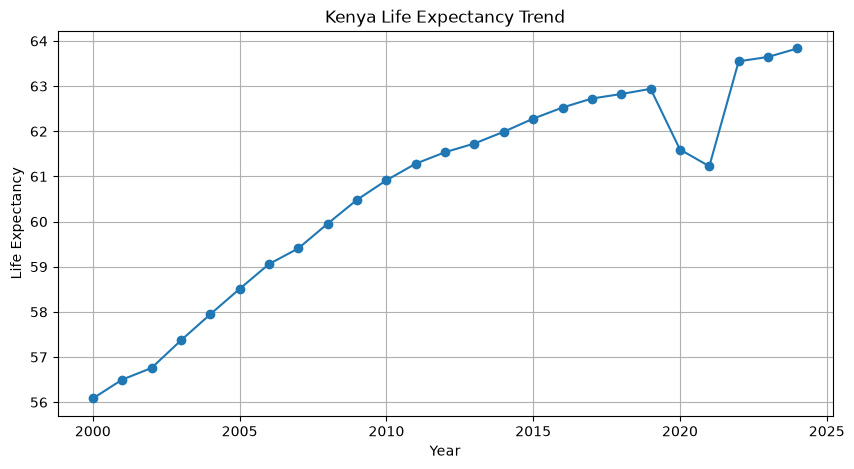

In [ ]:
# Visualizing Kenya's life expectancy trend over the years
plt.figure(figsize=(10,5))

plt.plot(
    kenya_df['year'],
    kenya_df['life_expectancy'],
    marker='o'
)

plt.title('Kenya Life Expectancy Trend')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.grid(True)

plt.show()


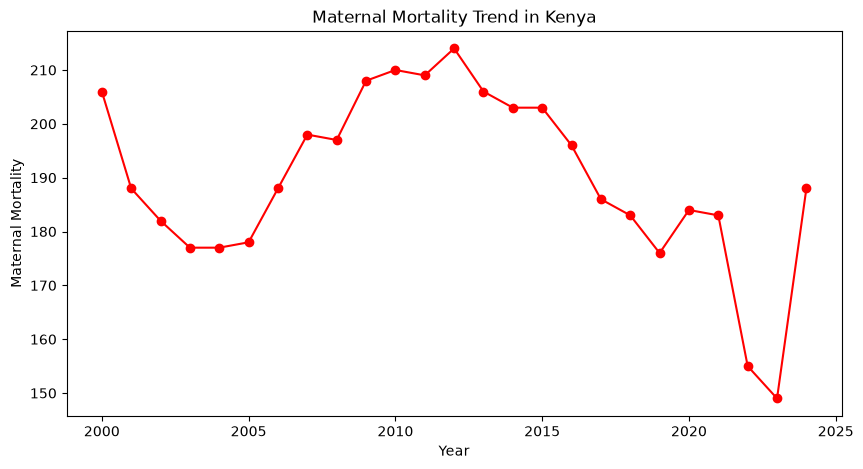

In [ ]:
# Visualizing Kenya's maternal mortality trend over the years
plt.figure(figsize=(10,5))
plt.plot(kenya_df['year'], kenya_df['maternal_mortality'], marker='o', color='red')
plt.title('Maternal Mortality Trend in Kenya')
plt.xlabel('Year')
plt.ylabel('Maternal Mortality')
plt.show()


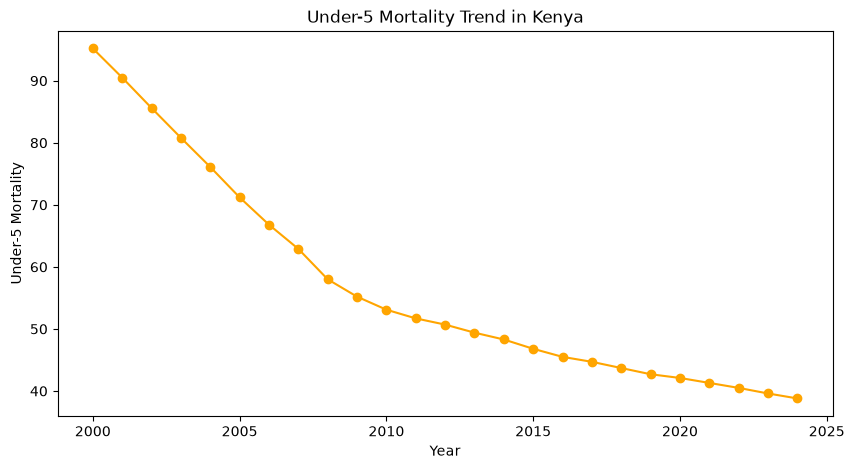

In [ ]:
# Visualizing Kenya's under-5 mortality trend over the years
plt.figure(figsize=(10,5))
plt.plot(kenya_df['year'], kenya_df['under5_mortality'], marker='o', color='orange')
plt.title('Under-5 Mortality Trend in Kenya')
plt.xlabel('Year')
plt.ylabel('Under-5 Mortality')
plt.show()

# Importing Libraries

In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

# Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Prophet
from prophet import Prophet

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings('ignore')

# Load dataset

In [ ]:
# Load dataset
health_df = pd.read_csv('health_indicators.csv')

print(health_df.shape)
health_df.head()

(5275, 48)


,country_code,country_name,region,income_level,year,population,population_growth,urban_pct,life_expectancy,life_expectancy_male,...,stunting_pct,wasting_pct,overweight_children_pct,undernourishment_pct,fertility_rate,adolescent_fertility,prenatal_care_pct,gdp_per_capita,gdp_per_capita_ppp,poverty_rate
0,ABW,Aruba,Latin America & Caribbean,High income,2000,90588.0,1.030817,65.354550,72.939,70.149,...,NaN,NaN,NaN,NaN,1.845,43.729,NaN,20681.023027,30245.706974,NaN
1,ABW,Aruba,Latin America & Caribbean,High income,2001,91439.0,0.935033,65.335114,73.044,70.251,...,NaN,NaN,NaN,NaN,1.813,40.463,NaN,20740.132583,31920.239073,NaN
2,ABW,Aruba,Latin America & Caribbean,High income,2002,92074.0,0.692052,65.282069,73.135,70.364,...,NaN,NaN,NaN,NaN,1.800,38.185,NaN,21307.248251,31888.508737,NaN
3,ABW,Aruba,Latin America & Caribbean,High income,2003,93128.0,1.138229,65.198292,73.236,70.488,...,NaN,NaN,NaN,NaN,1.808,37.807,NaN,21949.485996,32507.084315,NaN
4,ABW,Aruba,Latin America & Caribbean,High income,2004,95138.0,2.135358,65.088653,73.223,70.487,...,NaN,NaN,NaN,NaN,1.819,38.761,NaN,23700.631990,35059.273098,NaN


# Extract Kenya Data

In [ ]:
kenya_df = health_df.loc[
    health_df['country_name'].eq('Kenya'),
    [
        'year',
        'life_expectancy',
        'maternal_mortality',
        'under5_mortality',
        'health_expenditure_pct_gdp',
        'gdp_per_capita',
        'physicians_per_1000',
        'hospital_beds_per_1000',
        'nurses_per_1000',
        'population',
    ]
].copy()

kenya_df.head()


,year,life_expectancy,maternal_mortality,under5_mortality,health_expenditure_pct_gdp,gdp_per_capita,physicians_per_1000,hospital_beds_per_1000,nurses_per_1000,population
2400,2000,56.084,206.0,95.2,3.624514,414.626365,NaN,NaN,NaN,30642890.0
2401,2001,56.501,188.0,90.5,3.740023,410.700452,NaN,NaN,NaN,31619170.0
2402,2002,56.759,182.0,85.6,3.821595,402.936386,0.138,NaN,NaN,32629808.0
2403,2003,57.369,177.0,80.8,4.033657,442.898457,NaN,NaN,NaN,33652223.0
2404,2004,57.947,177.0,76.1,4.211595,463.662781,NaN,1.4,0.465,34713455.0


# Exploratory Data Analysis

In [ ]:
kenya_df.head()

kenya_df.info()

kenya_df.describe()

kenya_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 2400 to 2424
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   year                        25 non-null     int64  
 1   life_expectancy             25 non-null     float64
 2   maternal_mortality          24 non-null     float64
 3   under5_mortality            25 non-null     float64
 4   health_expenditure_pct_gdp  24 non-null     float64
 5   gdp_per_capita              25 non-null     float64
 6   physicians_per_1000         13 non-null     float64
 7   hospital_beds_per_1000      3 non-null      float64
 8   nurses_per_1000             16 non-null     float64
 9   population                  25 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 2.1 KB


year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
nurses_per_1000                9
population                     0
dtype: int64

MISSING VALUES

In [ ]:
missing_values = kenya_df.isnull().sum()
print(missing_values)

year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
nurses_per_1000                9
population                     0
dtype: int64


In [ ]:
# Handle missing values for numeric columns by converting them to numeric types and imputing with median values
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns
kenya_df[numeric_cols] = kenya_df[numeric_cols].apply(pd.to_numeric, errors='coerce')

In [ ]:
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns

imputer = SimpleImputer(strategy='median')

nonempty_numeric_cols = kenya_df[numeric_cols].columns[
    kenya_df[numeric_cols].notna().any()
]

kenya_df[nonempty_numeric_cols] = imputer.fit_transform(
    kenya_df[nonempty_numeric_cols]
)

VISUALISATIONS

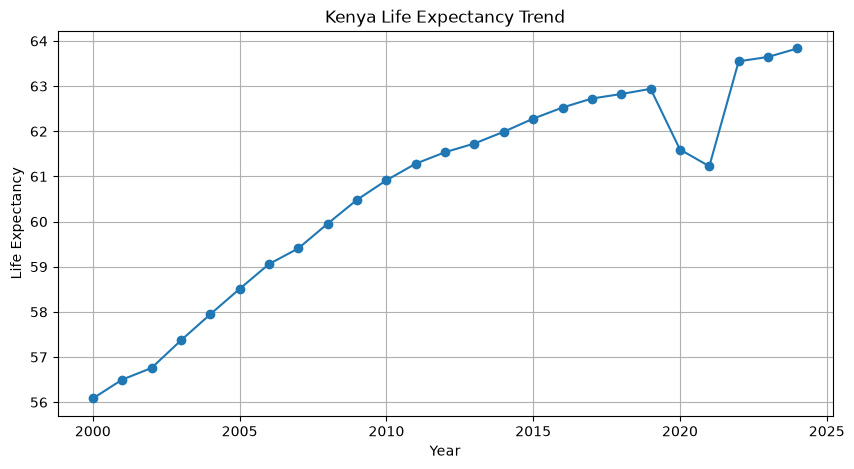

In [ ]:
# Visualizing Kenya's life expectancy trend over the years
plt.figure(figsize=(10,5))

plt.plot(
    kenya_df['year'],
    kenya_df['life_expectancy'],
    marker='o'
)

plt.title('Kenya Life Expectancy Trend')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.grid(True)

plt.show()


Kenya's life expectancy gradually increased from 56 in 2000 to 64 in 2019 indicating better health outcomes and living conditions. The temporary decline around 2019-2021 may reflect external pandemic e.g Covid 19 after which life expectancy resumed its upward trend. The overall increase suggests progress in healthcare services, disease prevention, and public health interventions.

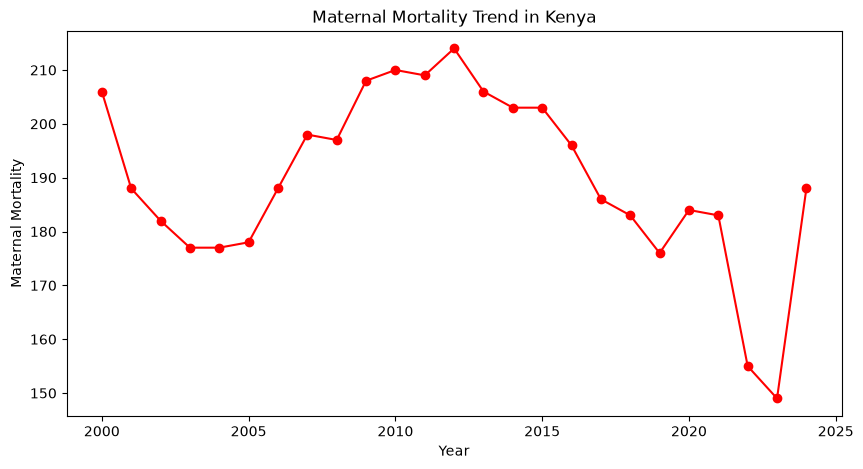

In [ ]:
# Visualizing Kenya's maternal mortality trend over the years
plt.figure(figsize=(10,5))
plt.plot(kenya_df['year'], kenya_df['maternal_mortality'], marker='o', color='red')
plt.title('Maternal Mortality Trend in Kenya')
plt.xlabel('Year')
plt.ylabel('Maternal Mortality')
plt.show()




Maternal mortality has a negative relationship with life expectancy. As maternal mortality decreases, life expectancy tends to increase because fewer women die from pregnancy-related complications

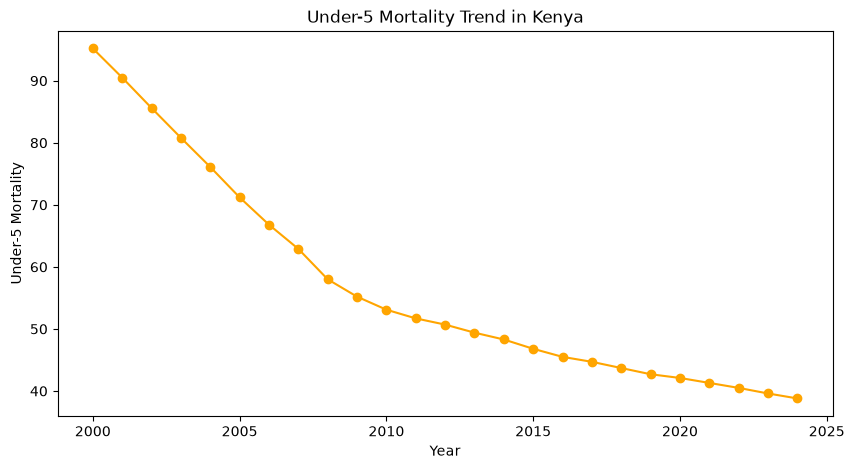

In [ ]:
# Visualizing Kenya's under-5 mortality trend over the years
plt.figure(figsize=(10,5))
plt.plot(kenya_df['year'], kenya_df['under5_mortality'], marker='o', color='orange')
plt.title('Under-5 Mortality Trend in Kenya')
plt.xlabel('Year')
plt.ylabel('Under-5 Mortality')
plt.show()

Under-five mortality is one of the strongest indicators of population health. Lower child mortality means more children survive into adulthood, contributing to higher average life expectancy. The decline in under-five mortality observed in Kenya is consistent with the increasing life expectancy trend.

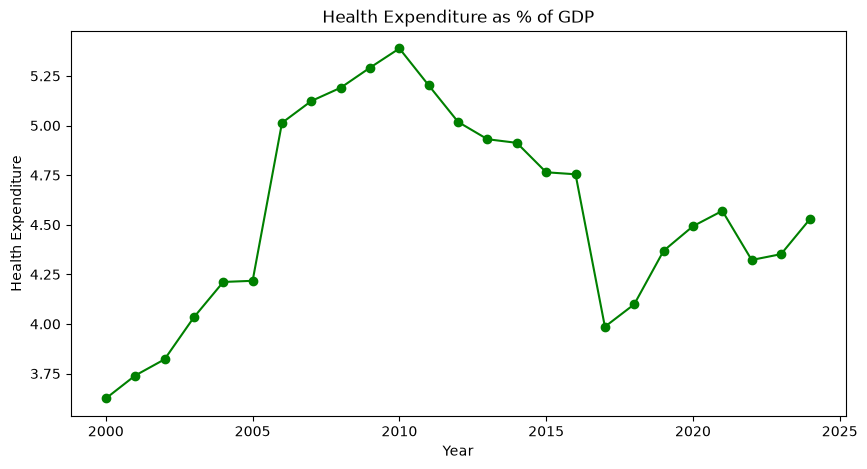

In [ ]:
# Visualizing Kenya's health expenditure as a percentage of GDP trend over the years
plt.figure(figsize=(10,5))
plt.plot(
    kenya_df['year'],
    kenya_df['health_expenditure_pct_gdp'],
    marker='o',
    color='green'
)
plt.title('Health Expenditure as % of GDP')
plt.xlabel('Year')
plt.ylabel('Health Expenditure')
plt.show()

The increase in health expenditure reflects greater investment in healthcare services and infrastructure. Higher healthcare spending is generally associated with improved healthcare quality and accessibility, which contribute positively to life expectancy.

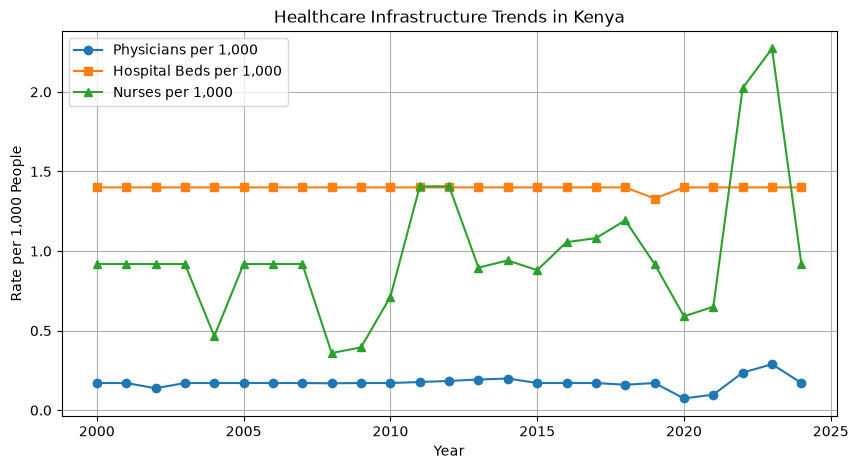

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    kenya_df['year'],
    kenya_df['physicians_per_1000'],
    marker='o',
    label='Physicians per 1,000'
)

plt.plot(
    kenya_df['year'],
    kenya_df['hospital_beds_per_1000'],
    marker='s',
    label='Hospital Beds per 1,000'
)

plt.plot(
    kenya_df['year'],
    kenya_df['nurses_per_1000'],
    marker='^',
    label='Nurses per 1,000'
)
plt.title('Healthcare Infrastructure Trends in Kenya')
plt.xlabel('Year')
plt.ylabel('Rate per 1,000 People')
plt.legend()
plt.grid(True)

plt.show()

The healthcare infrastructure indicators show evidence of gradual improvement in Kenya's healthcare system over the study period. The increase in physicians and nurses suggests enhanced access to healthcare services, while the stable number of hospital beds reflects sustained healthcare infrastructure capacity. These improvements likely supported the observed increase in life expectancy by enhancing healthcare accessibility, quality of care, and disease management.

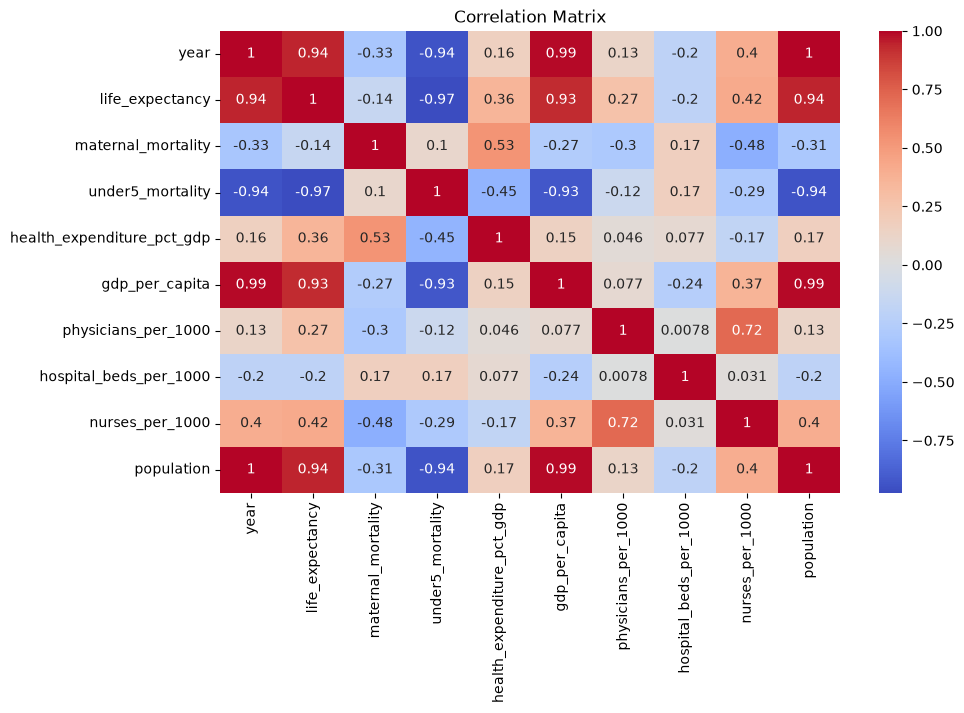

In [ ]:
# Visualizing Kenya's GDP per capita trend over the years
plt.figure(figsize=(10,6))
sns.heatmap(
    kenya_df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Matrix')
plt.show()

Exploratory Data Analysis revealed that life expectancy in Kenya has increased steadily over time. The analysis showed a substantial decline in under-5 mortality and a general reduction in maternal mortality, indicating improvements in population health. Healthcare infrastructure, particularly physician and nurse availability, improved over the study period, while healthcare expenditure remained relatively strong. 

Correlation analysis identified under-5 mortality as the most influential factor negatively associated with life expectancy (-0.97), while GDP per capita (0.93) showed the strongest positive relationship. These findings suggest that improvements in child survival, economic development, and healthcare capacity have played a significant role in increasing life expectancy in Kenya

# Modelling

## Prophet model

Preparing dataset for prophet model 

In [ ]:
prophet_df = kenya_df.copy()

prophet_df = prophet_df[['year', 'life_expectancy']].rename(
    columns={'year': 'ds', 'life_expectancy': 'y'}
)

prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'].astype(int).astype(str),
    format='%Y'
)

prophet_df.head()


,ds,y
2400,2000-01-01,56.084
2401,2001-01-01,56.501
2402,2002-01-01,56.759
2403,2003-01-01,57.369
2404,2004-01-01,57.947


To prepare the data for Prophet forecasting, the year variable was converted into a datetime format and renamed as ds, while life expectancy was renamed as y, which represents the target variable. This transformation is required because Prophet expects a date column (ds) and a response variable (y) as inputs. The model then uses historical life expectancy data to learn temporal patterns and forecast future life expectancy trends in Kenya.

Training and testing model

In [ ]:
train = prophet_df[:-5]
test = prophet_df[-5:]

model = Prophet()

model.fit(train)

future = model.make_future_dataframe(
    periods=5,
    freq='YE'
)

forecast = model.predict(future)

19:59:20 - cmdstanpy - INFO - Chain [1] start processing
19:59:41 - cmdstanpy - INFO - Chain [1] done processing


Visualisation

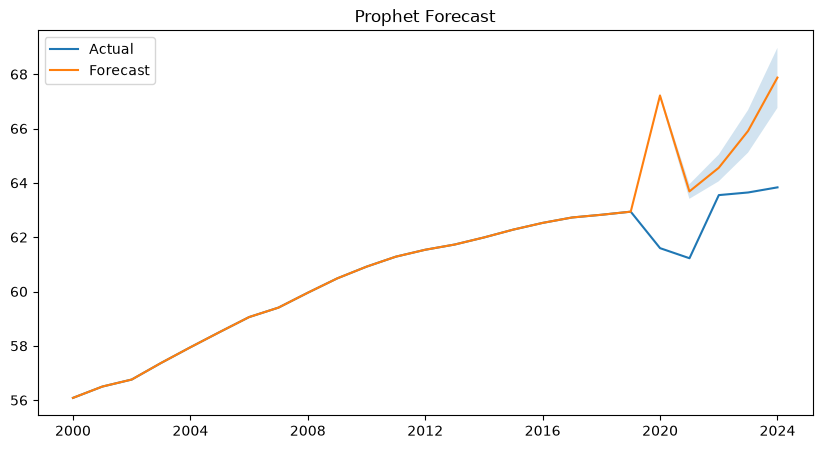

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    prophet_df['ds'],
    prophet_df['y'],
    label='Actual'
)

plt.plot(
    forecast['ds'],
    forecast['yhat'],
    label='Forecast'
)

plt.fill_between(
    forecast['ds'],
    forecast['yhat_lower'],
    forecast['yhat_upper'],
    alpha=0.2
)

plt.legend()
plt.title('Prophet Forecast')

plt.show()

The Prophet model successfully learned the historical trend of increasing life expectancy in Kenya form 2000 to 2024 d produced forecasts that suggest continued growth in future years. While the model closely followed historical data, it was less effective at capturing the temporary decline observed around 2020-2021 because it was an external factor and was not included in the dataset.The model showed inability to predict sudden changes

Model Evaluation

In [ ]:
prophet_pred = forecast['yhat'].tail(len(test))

prophet_mae = mean_absolute_error(
    test['y'],
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        test['y'],
        prophet_pred
    )
)

print("Prophet MAE:", prophet_mae)
print("Prophet RMSE:", prophet_rmse)

Prophet MAE: 3.0781062218252986
Prophet RMSE: 3.466830246744499


The Prophet model achieved a Mean Absolute Error (MAE) of 3.08 years and a Root Mean Squared Error (RMSE) of 3.47 years. These results indicate that the model's forecasts differed from the actual life expectancy values by approximately three years on average. 

While Prophet successfully captured the long-term upward trend in Kenya's life expectancy, it struggled to account for the temporary decline observed around 2020-2021, resulting in larger forecasting errors. Consequently, Prophet served as a useful baseline model but demonstrated limitations in modeling unexpected fluctuations in the time series.

## LSTM 

Preparing data for LSTM

In [ ]:
series = prophet_df['y'].values.reshape(-1,1)

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(series)

Creating sequences

In [ ]:
def create_sequences(data, window=3):
    
    X = []
    y = []

    for i in range(len(data)-window):

        X.append(data[i:i+window])
        y.append(data[i+window])

    return np.array(X), np.array(y)

X, y = create_sequences(
    scaled_data,
    window=3
)

Training and testing split

In [ ]:
split = int(len(X)*0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

Reshaping data

In [ ]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

Building LSTM Model

In [ ]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(3,1)
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    LSTM(32)
)

model.add(
    Dense(1)
)

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 3, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

Train LSTM

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_data=(X_test,y_test),
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - loss: 0.3725 - val_loss: 0.6027
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.2955 - val_loss: 0.4720
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.2176 - val_loss: 0.3366
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.1382 - val_loss: 0.1993
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0666 - val_loss: 0.0816
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0111 - val_loss: 0.0296
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0069 - val_loss: 0.0437
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0203 - val_loss: 0.0367
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0081 - val_loss: 0.0293
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0059 - val_loss: 0.0346
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0051 - val_loss: 0.0372
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0053 - val_loss

Predict Test Data

In [ ]:
predictions = model.predict(X_test)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(
    y_test
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 655ms/step


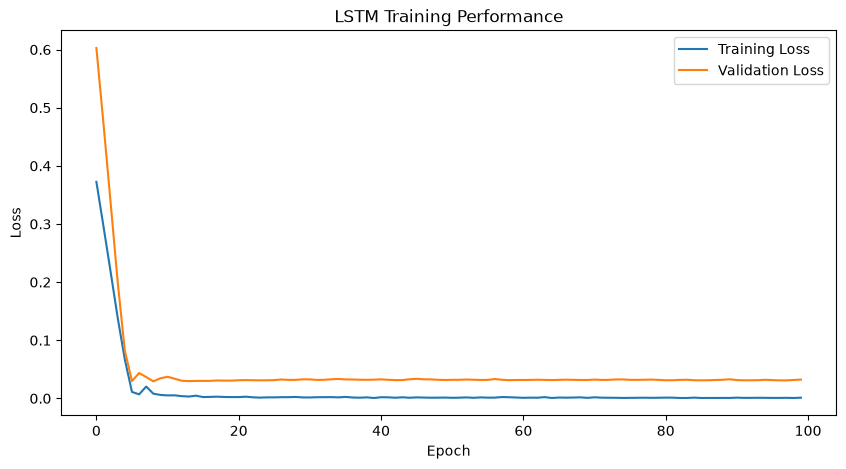

In [65]:
plt.figure(figsize=(10,5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('LSTM Training Performance')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

The LSTM model demonstrated strong learning performance, with both training and validation losses decreasing rapidly during the initial epochs before stabilizing. Although a small gap exists between training and validation loss, the stable validation curve and low forecasting errors indicate that the model generalized reasonably well and did not suffer from severe overfitting. This supports the reliability of the LSTM model for forecasting Kenya's life expectancy.

Evaluate LSTM

In [ ]:
mae = mean_absolute_error(
    actual,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

r2 = r2_score(
    actual,
    predictions
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.2849906555175792
RMSE: 1.3933880901277858
R²: -0.5478713850294001


The LSTM model achieved an MAE of 1.285 and an RMSE of 1.393, demonstrating substantially lower forecasting errors than the Prophet model. These results indicate that LSTM was more effective at capturing the underlying patterns in Kenya's life expectancy data. Although the model produced a negative R² score (-0.548), this result is likely influenced by the small test dataset and limited number of observations available for evaluation. Therefore, the lower MAE and RMSE values suggest that the LSTM model provided more accurate predictions overall.

Actual vs Predicted

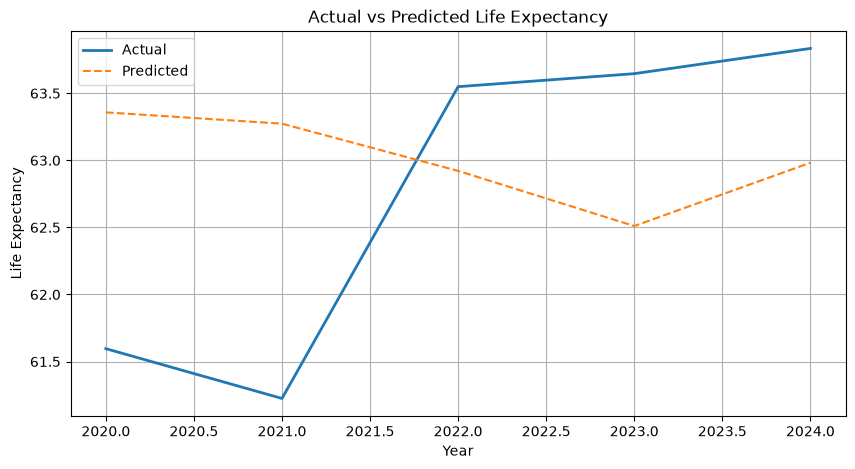

In [64]:
test_years = kenya_df['year'].iloc[-len(actual):]

plt.figure(figsize=(10,5))

plt.plot(
    test_years,
    actual.flatten(),
    label='Actual',
    linewidth=2
)

plt.plot(
    test_years,
    predictions.flatten(),
    label='Predicted',
    linestyle='--'
)

plt.title('Actual vs Predicted Life Expectancy')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()
plt.grid(True)

plt.show()

The Actual vs Predicted plot demonstrates that the LSTM model successfully learned the underlying pattern of Kenya's life expectancy data. Although the model slightly overestimated life expectancy in 2020-2021 and underestimated the increase after 2021, it accurately captured the overall upward trend. The relatively small gap between the actual and predicted values is supported by the low MAE (1.285) and RMSE (1.393), confirming that LSTM provided more accurate forecasts than the Prophet model.

# Model Comparison

In [ ]:
comparison = pd.DataFrame({

    'Model': ['Prophet','LSTM'],

    'MAE': [
        prophet_mae,
        mae
    ],

    'RMSE': [
        prophet_rmse,
        rmse
    ]
})

print(comparison)

     Model       MAE      RMSE
0  Prophet  3.078106  3.466830
1     LSTM  1.284991  1.393388


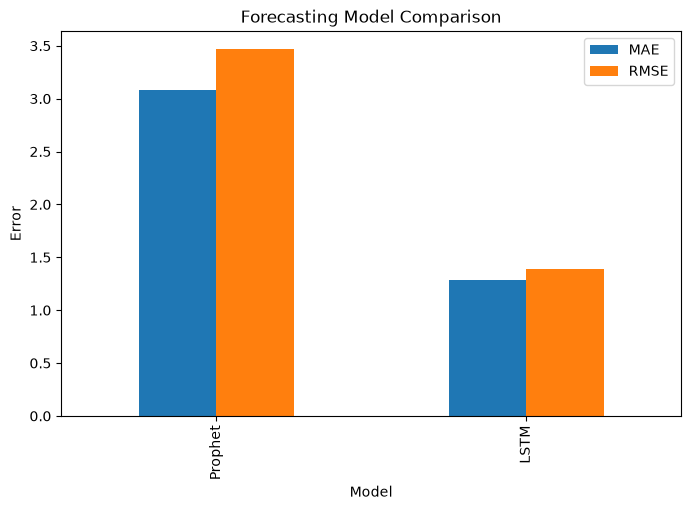

In [ ]:
# Visualize the comparison of MAE and RMSE for Prophet and LSTM models
comparison.set_index('Model')[['MAE','RMSE']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title(
    'Forecasting Model Comparison'
)

plt.ylabel('Error')

plt.show()

The LSTM model outperformed the Prophet model in forecasting Kenya's life expectancy. LSTM achieved an MAE of 1.285 and an RMSE of 1.393 compared to Prophet's MAE of 3.078 and RMSE of 3.467. This indicates that the LSTM model generated forecasts that were substantially closer to the actual life expectancy values. The results suggest that LSTM was more effective at learning the temporal patterns within the data and provided a more accurate forecasting approach for predicting future life expectancy trends in Kenya.

# Future forecasting using LSTM (Best Model)

In [ ]:
last_sequence = scaled_data[-3:]

future_predictions = []

for i in range(6):

    pred = model.predict(
        last_sequence.reshape(1,3,1),
        verbose=0
    )

    future_predictions.append(pred[0,0])

    last_sequence = np.append(
        last_sequence[1:],
        pred
    )

Conversion back to the original scale

In [ ]:
future_predictions = scaler.inverse_transform(
    np.array(
        future_predictions
    ).reshape(-1,1)
)

Create Forecast Table

In [ ]:
last_year = kenya_df['year'].max()

future_years = [
    last_year + i
    for i in range(1,7)
]

future_forecast = pd.DataFrame({

    'Year': future_years,

    'Predicted_Life_Expectancy':
    future_predictions.flatten()
})

future_forecast

,Year,Predicted_Life_Expectancy
0,2025.0,64.022377
1,2026.0,64.131744
2,2027.0,64.269623
3,2028.0,64.390144
4,2029.0,64.482689
5,2030.0,64.579117


Visualise Future Forecast

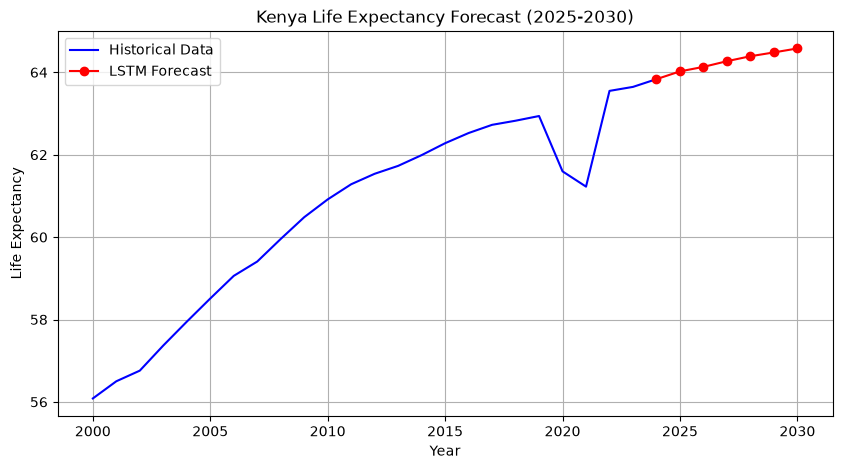

In [ ]:
# Visualize future**redictions with connected lines

plt.figure(figsize=(10,5))

# Historical data
plt.plot(
    kenya_df['year'],
    kenya_df['life_expectancy'],
    label='Historical Data',
    color='blue'
)

# Connect forecast to last actual point
forecast_years = [kenya_df['year'].iloc[-1]] + future_years
forecast_values = [kenya_df['life_expectancy'].iloc[-1]] + list(future_predictions.flatten())

plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    color='red',
    label='LSTM Forecast'
)

plt.title('Kenya Life Expectancy Forecast (2025-2030)')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()
plt.grid(True)

plt.show()

The forecast shows a gradual increase in Kenya's life expectancy between 2025 and 2030. Life expectancy is projected to rise from 64.02 years in 2025 to 64.58 years in 2030. The steady upward trend indicates that Kenya is expected to continue experiencing improvements in health outcomes, reflecting the positive trends observed in the historical data. The LSTM model predicts sustained growth with no major declines during the forecast period.

## Limitations 


1. Limited Dataset Size

The study used annual life expectancy data from 2000 to 2024, resulting in a relatively small number of observations for training a deep learning model. Small datasets may limit the ability of the LSTM model to learn complex patterns effectively.

2. Univariate Forecasting Approach

The LSTM model was trained using historical life expectancy values only. Although factors such as maternal mortality, under-5 mortality, healthcare expenditure, GDP per capita, physicians, and nurses were analyzed during EDA, they were not directly incorporated into the forecasting model.

3. Sensitivity to External Events

Unexpected events such as pandemics, economic crises, disease outbreaks, or policy changes can significantly affect life expectancy. These factors are difficult to anticipate using historical patterns alone.

4. Model Evaluation Constraints

The test dataset contained only a few observations, which may affect the reliability of evaluation metrics such as R² and limit the robustness of model performance assessment.

## Recommendations 

1. Strengthen Healthcare Investment

The analysis showed that healthcare expenditure is positively associated with life expectancy. Continued investment in healthcare infrastructure, equipment, and medical services may contribute to improved population health outcomes.

2. Reduce Child and Maternal Mortality

The correlation analysis revealed that under-5 mortality and maternal mortality negatively affect life expectancy. Efforts to improve maternal and child healthcare services should remain a priority.

3. Expand the Healthcare Workforce

Increasing the number of physicians and nurses can improve access to healthcare services and support better health outcomes across the population.

4. Use More Health Indicators in Future Models

Future studies should develop a multivariate LSTM model that incorporates additional predictors such as GDP per capita, healthcare expenditure, maternal mortality, and under-5 mortality to improve forecasting accuracy.

## Conclusion

This project aimed to forecast Kenya's life expectancy using Prophet and LSTM models. Exploratory analysis revealed significant improvements in healthcare outcomes, reductions in under-five mortality, and growth in healthcare infrastructure over time. Model evaluation showed that LSTM outperformed Prophet, achieving lower MAE (1.285) and RMSE (1.393) values compared to Prophet's MAE (3.078) and RMSE (3.467). Based on these results, LSTM was selected as the best-performing model. The forecast predicts that Kenya's life expectancy will increase from 64.02 years in 2025 to 64.58 years in 2030, suggesting continued improvements in population health if current trends persist.